# Final Model: Monthly Rent Price Prediction

**Team 4:** Dariya, Bakai, Rimma, Niyaz. **Notebook author:** Niyaz.

This notebook is the complete workflow from loading the data to writing `predictions.csv`. It builds on the team's notebooks:

| Notebook | Content |
|---|---|
| `01_data_preprocessing.ipynb` | data checks, shared split, preprocessing, Linear Regression |
| `02_decision_tree.ipynb` | Decision Tree with Grid Search |
| `03_random_forest.ipynb` | Random Forest with Grid Search and feature engineering |
| `04_gradient_boosting.ipynb` | Gradient Boosting with Grid Search and a log-transformed target |
| `05_model_comparison.ipynb` | comparison of all models under one protocol |

**Workflow:**
1. Load and explore the data
2. Validation protocol
3. Starting point: the four required models with their tuned hyperparameters
4. Feature engineering: neighborhood price level
5. Grid Search for the models with the new features
6. Ensembles
7. Final comparison and model selection
8. Final training and predictions for `challenge1_test.csv`

## 1. Load and explore the data

In [1]:
import time
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import BallTree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, VotingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats

RANDOM_STATE = 42

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

train_df = pd.read_csv("../data/challenge1_train.csv")
test_df = pd.read_csv("../data/challenge1_test.csv")
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Missing values in train:", int(train_df.isna().sum().sum()), "| duplicate rows:", int(train_df.duplicated().sum()))
train_df.head()

Train: (7398, 10) | Test: (2467, 9)
Missing values in train: 0 | duplicate rows: 0


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


In [2]:
price = train_df["price"]
print(f"Price: median {price.median():,.0f}, mean {price.mean():,.0f}, std {price.std():,.0f}, max {price.max():,.0f}")
print(f"Skewness: price {price.skew():.2f}, log(price) {np.log(price).skew():.2f}")

print("\ncategory:", train_df["category"].value_counts().to_dict())
print("has_photo:", train_df["has_photo"].value_counts().to_dict())
print("states:", train_df["state"].nunique())

loc = train_df["latitude"].round(4).astype(str) + "," + train_df["longitude"].round(4).astype(str)
per_loc = train_df.groupby(loc)["price"].agg(["size", "std"])
shared = per_loc["size"] > 1
print(f"\nUnique coordinates: {len(per_loc):,} for {len(train_df):,} listings")
print(f"Listings that share their coordinates with another listing: {per_loc.loc[shared, 'size'].sum() / len(train_df):.0%}")
print(f"Median price std within a shared location: {per_loc.loc[shared, 'std'].median():,.0f} "
      f"(overall price std: {price.std():,.0f})")

Price: median 1,274, mean 1,463, std 822, max 8,800
Skewness: price 2.71, log(price) 0.54

category: {'housing/rent/apartment': 7395, 'housing/rent/home': 2, 'housing/rent/short_term': 1}
has_photo: {'Thumbnail': 6566, 'Yes': 693, 'No': 139}
states: 50

Unique coordinates: 2,036 for 7,398 listings
Listings that share their coordinates with another listing: 86%
Median price std within a shared location: 247 (overall price std: 822)


**Observations**

- The data is clean: no missing values and no duplicate rows. The target is right-skewed (skewness 2.71, 0.54 on the log scale), which is why the Gradient Boosting in `04` is trained on `log(price)`.
- `category` is almost constant (3 of 7,398 listings are not apartments) and `has_photo` has three levels. Both are kept with one-hot encoding, as in the team notebooks.
- **Location has a strong structure.** The 7,398 listings sit at only 2,036 distinct coordinates, and 86% of them share their coordinates with at least one other listing (the same building or complex). At a shared location the median price standard deviation is 247, against 822 overall. The prices of other listings at the same place therefore say a lot about a listing's price; section 4 turns this into features.

## 2. Validation protocol

The same protocol as in every team notebook:
- **Split:** 80/20 hold-out with `random_state=42`: 5,918 training rows for development, 1,480 validation rows.
- **CV RMSE (primary selection metric):** 5-fold `KFold(shuffle=True, random_state=42)` on the training part, used for Grid Search and model selection. Reported as mean and standard deviation over folds.
- **Validation RMSE:** the model is refit on the training part and scored once on the validation set. The validation set is never used for tuning or selection; it is an independent check of the CV estimate.
- All preprocessing and feature engineering are inside scikit-learn pipelines, so they are fit on training folds only.
- `challenge1_test.csv` is used only in section 8 to produce the final predictions.

In [3]:
X = train_df.drop(columns=["price", "ID"])
y = train_df["price"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("X_train:", X_train.shape, "| X_val:", X_val.shape)

X_train: (5918, 8) | X_val: (1480, 8)


## 3. Starting point: the four required models

Each model uses the preprocessing and the Grid Search result from its notebook:

- **Linear Regression** (`01`): standardized numeric features, one-hot encoded categoricals.
- **Decision Tree** (`02`): same preprocessing, tuned depth, leaf size and pruning.
- **Random Forest** (`03`): unscaled numeric features (trees do not need scaling), one-hot categoricals, tuned forest.
- **Gradient Boosting** (`04`): same as Random Forest, tuned boosting hyperparameters, trained on `log(price)`.

`evaluate` applies the protocol from section 2 and keeps the out-of-fold predictions (each training row predicted by the model that did not see it) for the paired comparisons and ensembles later.

In [4]:
numeric_features = ["bathrooms", "bedrooms", "square_feet", "latitude", "longitude"]
categorical_features = ["category", "has_photo", "state"]

DT_TUNED = {"max_depth": 15, "min_samples_leaf": 5, "min_samples_split": 2, "ccp_alpha": 50.0}  # 02
RF_TUNED = {"n_estimators": 400, "max_depth": 20, "min_samples_leaf": 1, "max_features": 0.33}  # 03
GB_LOG_TUNED = {"n_estimators": 1000, "learning_rate": 0.1, "max_depth": 5, "min_samples_leaf": 5,
                "subsample": 0.8, "max_features": 0.5}  # 04, log target


def scaled_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])


def tree_preprocessor(extra=()):
    # extra: additional (name, transformer, columns) steps, used for the engineered features in section 4
    return ColumnTransformer([
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        *extra,
    ])


def log_target(regressor):
    # fit on log(price), predict exp(prediction); wraps only the regressor, so it is applied inside every CV fold
    return TransformedTargetRegressor(regressor=regressor, func=np.log, inverse_func=np.exp)


def make_lr():
    return Pipeline([("prep", scaled_preprocessor()), ("model", LinearRegression())])

def make_dt():
    return Pipeline([("prep", scaled_preprocessor()),
                     ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, **DT_TUNED))])

def make_rf(extra=(), **params):
    return Pipeline([("prep", tree_preprocessor(extra)),
                     ("model", RandomForestRegressor(**{"random_state": RANDOM_STATE, "n_jobs": -1, **RF_TUNED, **params}))])

def make_gb(extra=(), **params):
    return Pipeline([("prep", tree_preprocessor(extra)),
                     ("model", log_target(GradientBoostingRegressor(random_state=RANDOM_STATE, **{**GB_LOG_TUNED, **params})))])

In [5]:
@dataclass
class Result:
    name: str
    model: object  # fitted on the training part
    fold_rmse: np.ndarray
    oof_pred: np.ndarray
    val_pred: np.ndarray
    fit_time: float


results, builders = {}, {}


def evaluate(name, build):
    # build: zero-argument function returning a fresh, unfitted model
    builders[name] = build
    estimator = build()
    fold_rmse, oof_pred = [], np.zeros(len(y_train))
    for tr_idx, va_idx in cv.split(X_train):
        fold_model = clone(estimator).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        oof_pred[va_idx] = fold_model.predict(X_train.iloc[va_idx])
        fold_rmse.append(rmse(y_train.iloc[va_idx], oof_pred[va_idx]))
    t0 = time.perf_counter()
    model = clone(estimator).fit(X_train, y_train)
    fit_time = time.perf_counter() - t0
    results[name] = Result(name, model, np.array(fold_rmse), oof_pred, model.predict(X_val), fit_time)
    r = results[name]
    print(f"{name:42s} CV RMSE {r.fold_rmse.mean():7.2f} ± {r.fold_rmse.std(ddof=1):5.2f} | "
          f"validation RMSE {rmse(y_val, r.val_pred):7.2f}")


def table(names):
    rows = []
    for n in names:
        r = results[n]
        rows.append({
            "Model": n,
            "CV RMSE": r.fold_rmse.mean(),
            "CV std": r.fold_rmse.std(ddof=1),
            "Validation RMSE": rmse(y_val, r.val_pred),
            "Validation MAE": mean_absolute_error(y_val, r.val_pred),
            "Validation R2": r2_score(y_val, r.val_pred),
            "Fit time (s)": r.fit_time,
        })
    return pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE").round(2)


evaluate("Linear Regression", make_lr)
evaluate("Decision Tree (tuned)", make_dt)
evaluate("Random Forest (tuned)", make_rf)
evaluate("Gradient Boosting (tuned, log target)", make_gb)
starting_point = list(results)
table(starting_point)

Linear Regression                          CV RMSE  520.94 ± 35.69 | validation RMSE  549.97


Decision Tree (tuned)                      CV RMSE  482.37 ± 16.53 | validation RMSE  503.72


Random Forest (tuned)                      CV RMSE  412.53 ± 24.13 | validation RMSE  444.88


Gradient Boosting (tuned, log target)      CV RMSE  383.91 ± 14.12 | validation RMSE  405.94


,CV RMSE,CV std,Validation RMSE,Validation MAE,Validation R2,Fit time (s)
Model,,,,,,
"Gradient Boosting (tuned, log target)",383.91,14.12,405.94,240.01,0.77,2.38
Random Forest (tuned),412.53,24.13,444.88,260.83,0.73,0.67
Decision Tree (tuned),482.37,16.53,503.72,306.36,0.65,0.02
Linear Regression,520.94,35.69,549.97,349.20,0.58,0.01


These are the same numbers as in `05_model_comparison.ipynb`. Gradient Boosting trained on `log(price)` is the best required model (CV RMSE 383.91, validation 405.94), followed by Random Forest (412.53 / 444.88), the Decision Tree (482.37 / 503.72) and Linear Regression (520.94 / 549.97). This is the baseline the improvements below have to beat.

## 4. Feature engineering: neighborhood price level

**Idea.** Location is the strongest driver of rent, but the models only see raw latitude and longitude, and trees have to approximate the price surface with many axis-aligned splits. Section 1 showed that many listings share a building or a block and that prices at the same location vary much less than prices overall. The price level of the nearest *training* listings is therefore a strong, direct summary of location.

`NeighborhoodFeatures` finds the `k` nearest training listings by great-circle (haversine) distance and adds three features:
- `nbr_log_price_per_sqft`: mean log(price / square_feet) of the neighbors, the local price level independent of size;
- `nbr_log_price`: mean log(price) of the neighbors;
- `nbr_dist_km`: mean distance to the neighbors, i.e. how dense and reliable the neighborhood estimate is.

**No leakage.** The features use training labels, so they are built like out-of-fold target encoding:
- `fit_transform` (training rows) splits the rows it receives into 5 internal folds and computes each row's features from the other folds only, so a row never sees its own price;
- `transform` (validation, test or CV hold-out rows) uses all rows the transformer was fit on.

Because the transformer is a pipeline step, in cross-validation it only ever sees the labels of the training folds, and the CV hold-out fold is treated exactly like unseen test data.

In [6]:
EARTH_RADIUS_KM = 6371.0


class NeighborhoodFeatures(BaseEstimator, TransformerMixin):
    # input columns: latitude, longitude, square_feet

    def __init__(self, k=10, n_splits=5, random_state=RANDOM_STATE):
        self.k = k
        self.n_splits = n_splits
        self.random_state = random_state

    @staticmethod
    def _coords(X):
        return np.radians(X[["latitude", "longitude"]].to_numpy(dtype=float))

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        self.coords_ = self._coords(X)
        self.log_price_ = np.log(y)
        self.log_ppsf_ = np.log(y / X["square_feet"].to_numpy(dtype=float))
        self.tree_ = BallTree(self.coords_, metric="haversine")
        return self

    def _features(self, tree, idx_map, coords):
        dist, idx = tree.query(coords, k=self.k)
        idx = idx_map[idx]
        return np.column_stack([
            self.log_ppsf_[idx].mean(axis=1),
            self.log_price_[idx].mean(axis=1),
            dist.mean(axis=1) * EARTH_RADIUS_KM,
        ])

    def transform(self, X):
        return self._features(self.tree_, np.arange(len(self.coords_)), self._coords(X))

    def fit_transform(self, X, y):
        # out-of-fold features for the rows used to fit: no row sees its own price
        self.fit(X, y)
        out = np.empty((len(self.coords_), 3))
        folds = KFold(self.n_splits, shuffle=True, random_state=self.random_state)
        for fit_idx, oof_idx in folds.split(self.coords_):
            tree = BallTree(self.coords_[fit_idx], metric="haversine")
            out[oof_idx] = self._features(tree, fit_idx, self.coords_[oof_idx])
        return out

    def get_feature_names_out(self, input_features=None):
        return np.array(["nbr_log_price_per_sqft", "nbr_log_price", "nbr_dist_km"], dtype=object)


def nbr(k=10):
    return [("nbr", NeighborhoodFeatures(k=k), ["latitude", "longitude", "square_feet"])]


# sanity check: the features of validation rows come only from training rows
check = NeighborhoodFeatures(k=10).fit(X_train, y_train)
pd.DataFrame(check.transform(X_val.head()), columns=check.get_feature_names_out(), index=X_val.head().index).round(3)

,nbr_log_price_per_sqft,nbr_log_price,nbr_dist_km
2473,0.762,7.332,22.582
6730,0.188,7.003,33.584
2847,0.535,6.935,0.000
169,0.315,7.024,3.657
2036,0.601,7.429,5.710


First, the new features are added to the tuned Random Forest and Gradient Boosting without changing any hyperparameter (`k=10`), so the change in RMSE comes from the features alone.

In [7]:
evaluate("Random Forest + neighborhood (k=10)", lambda: make_rf(extra=nbr(10)))
evaluate("Gradient Boosting + neighborhood (k=10)", lambda: make_gb(extra=nbr(10)))
table(starting_point + ["Random Forest + neighborhood (k=10)", "Gradient Boosting + neighborhood (k=10)"])

Random Forest + neighborhood (k=10)        CV RMSE  388.28 ± 24.13 | validation RMSE  410.46


Gradient Boosting + neighborhood (k=10)    CV RMSE  392.06 ± 21.10 | validation RMSE  404.48


,CV RMSE,CV std,Validation RMSE,Validation MAE,Validation R2,Fit time (s)
Model,,,,,,
"Gradient Boosting (tuned, log target)",383.91,14.12,405.94,240.01,0.77,2.38
Random Forest + neighborhood (k=10),388.28,24.13,410.46,244.28,0.77,1.14
Gradient Boosting + neighborhood (k=10),392.06,21.10,404.48,244.32,0.77,4.26
Random Forest (tuned),412.53,24.13,444.88,260.83,0.73,0.67
Decision Tree (tuned),482.37,16.53,503.72,306.36,0.65,0.02
Linear Regression,520.94,35.69,549.97,349.20,0.58,0.01


**Observations**

- **Random Forest benefits strongly:** CV RMSE falls by 24.3 (412.53 to 388.28) and validation RMSE by 34.4 (444.88 to 410.46). A forest of deep trees on raw coordinates has no direct way to express how expensive an area is; the neighborhood features give it that directly.
- **Gradient Boosting does not, with unchanged hyperparameters:** CV RMSE 392.06 against 383.91 without the features (validation 404.48 against 405.94). Boosted depth-5 trees on latitude and longitude already model the local price level well, so the new features mostly repeat that information. Section 5 re-tunes both models for the new features.

## 5. Grid Search with the new features

The new features change what the trees need to learn, so the most relevant hyperparameters are re-tuned together with the number of neighbors `k`. The grids are small because the rest of the hyperparameters were already tuned in `03` and `04`.

In [8]:
def grid_search(estimator, param_grid):
    grid = GridSearchCV(estimator, param_grid, scoring="neg_root_mean_squared_error", cv=cv,
                        n_jobs=-1, return_train_score=True)
    t0 = time.time()
    grid.fit(X_train, y_train)
    res = pd.DataFrame(grid.cv_results_)
    res = res[[c for c in res if c.startswith("param_")] + ["mean_train_score", "mean_test_score", "std_test_score"]]
    res.columns = [c.removeprefix("param_").split("__")[-1] for c in res.columns[:-3]] + ["train_rmse", "cv_rmse", "cv_std"]
    res[["train_rmse", "cv_rmse"]] *= -1
    print(f"Grid Search time: {(time.time() - t0) / 60:.1f} min | best CV RMSE {-grid.best_score_:.2f}")
    print("Best params:", {k.split("__")[-1]: v for k, v in grid.best_params_.items()})
    return grid, res.sort_values("cv_rmse").round(2)


# n_jobs=1: the Grid Search already runs the fits in parallel (results do not depend on n_jobs)
rf_grid, rf_res = grid_search(make_rf(extra=nbr(), n_jobs=1), {
    "prep__nbr__k": [5, 10, 20],
    "model__max_features": [0.33, 0.5],
    "model__min_samples_leaf": [1, 3],
})
rf_res.head(5)

Grid Search time: 1.0 min | best CV RMSE 388.28
Best params: {'max_features': 0.33, 'min_samples_leaf': 1, 'k': 10}


,max_features,min_samples_leaf,k,train_rmse,cv_rmse,cv_std
1,0.33,1,10,256.42,388.28,21.58
0,0.33,1,5,273.76,388.89,20.19
10,0.50,3,10,297.42,390.32,22.67
7,0.50,1,10,257.13,390.88,22.36
4,0.33,3,10,304.74,390.89,23.16


In [9]:
gb_grid, gb_res = grid_search(make_gb(extra=nbr()), {
    "prep__nbr__k": [5, 10, 20],
    "model__regressor__max_depth": [3, 5, 8],
    "model__regressor__learning_rate": [0.05, 0.1],
})
gb_res.head(5)

Grid Search time: 1.0 min | best CV RMSE 383.13
Best params: {'learning_rate': 0.05, 'max_depth': 3, 'k': 5}


,learning_rate,max_depth,k,train_rmse,cv_rmse,cv_std
0,0.05,3,5,305.96,383.13,14.67
9,0.10,3,5,295.72,383.57,14.10
4,0.05,5,10,268.48,384.78,19.78
3,0.05,5,5,281.51,384.96,18.83
1,0.05,3,10,307.30,386.95,20.01


In [10]:
RF_NBR = {k.split("__")[-1]: v for k, v in rf_grid.best_params_.items()}  # n_jobs is back to -1 below
GB_NBR = {k.split("__")[-1]: v for k, v in gb_grid.best_params_.items()}

rf_k = RF_NBR.pop("k")
gb_k = GB_NBR.pop("k")
evaluate("Random Forest + neighborhood (tuned)", lambda: make_rf(extra=nbr(rf_k), **RF_NBR))
evaluate("Gradient Boosting + neighborhood (tuned)", lambda: make_gb(extra=nbr(gb_k), **GB_NBR))

Random Forest + neighborhood (tuned)       CV RMSE  388.28 ± 24.13 | validation RMSE  410.46


Gradient Boosting + neighborhood (tuned)   CV RMSE  383.13 ± 16.41 | validation RMSE  415.36


**Observations**

- **Random Forest:** the Grid Search confirms the hyperparameters from `03` and `k=10` (CV RMSE 388.28); the top five settings are within 2.6 of each other, and `k=5` is almost as good.
- **Gradient Boosting** with neighborhood features prefers shallower trees and a lower learning rate (`max_depth=3`, `learning_rate=0.05`, `k=5`). Once the local price level is given as a feature, simpler trees are enough. Its CV RMSE (383.13) is now on par with Gradient Boosting without the features (383.91), but its validation RMSE (415.36) is higher.
- On their own, neither model with neighborhood features is clearly better than Gradient Boosting without them. They model location in a different way, which is what makes them useful in an ensemble (section 6).

## 6. Ensembles

Random Forest (bagging of deep trees) and Gradient Boosting (sequential small trees on the log scale) make different kinds of errors, and the models with and without the neighborhood features look at location differently. Averaging models whose errors are not perfectly correlated usually reduces the variance part of the error.

Every combination of two or three of the strongest models is averaged with equal weights (no weights are tuned, to avoid overfitting the CV folds). Averaging the out-of-fold predictions is exactly what a `VotingRegressor` of the member pipelines produces in each fold, because every member is trained on the same rows. The best pair and the three-model average are then rebuilt as real `VotingRegressor` models and evaluated with the full protocol. In their names, GB is Gradient Boosting (tuned, log target), RF + nbr and GB + nbr are the tuned models with neighborhood features.

In [11]:
members = ["Gradient Boosting (tuned, log target)",
           "Random Forest + neighborhood (tuned)",
           "Gradient Boosting + neighborhood (tuned)"]

print("Correlation of out-of-fold errors:")
errors = pd.DataFrame({m: results[m].oof_pred - y_train.to_numpy() for m in members})
display(errors.corr().round(2))

from itertools import combinations

rows = []
for size in (2, 3):
    for combo in combinations(members, size):
        avg = np.mean([results[m].oof_pred for m in combo], axis=0)
        folds = [rmse(y_train.iloc[va], avg[va]) for _, va in cv.split(X_train)]
        rows.append({"Members": combo, "Average of": " + ".join(combo),
                     "CV RMSE": np.mean(folds), "CV std": np.std(folds, ddof=1)})
screen = pd.DataFrame(rows).sort_values("CV RMSE").reset_index(drop=True)
screen.drop(columns="Members").round(2)

Correlation of out-of-fold errors:


,"Gradient Boosting (tuned, log target)",Random Forest + neighborhood (tuned),Gradient Boosting + neighborhood (tuned)
"Gradient Boosting (tuned, log target)",1.00,0.87,0.85
Random Forest + neighborhood (tuned),0.87,1.00,0.90
Gradient Boosting + neighborhood (tuned),0.85,0.90,1.00


,Average of,CV RMSE,CV std
0,"Gradient Boosting (tuned, log target) + Random...",368.34,17.38
1,"Gradient Boosting (tuned, log target) + Gradie...",368.77,14.03
2,"Gradient Boosting (tuned, log target) + Random...",373.24,18.08
3,Random Forest + neighborhood (tuned) + Gradien...,375.78,20.65


**Observations**

- The out-of-fold errors of the three models are strongly but not perfectly correlated (0.85 to 0.90). The least correlated pair is Gradient Boosting with and without neighborhood features (0.85): the same algorithm with two different views of location.
- Every average beats every single model: CV RMSE 368 to 376, against 383 for the best single model. The best pair (GB, GB + nbr) at 368.77 and the three-model average at 368.34 are practically equal.

In [12]:
short = {
    "Gradient Boosting (tuned, log target)": "GB",
    "Random Forest + neighborhood (tuned)": "RF + nbr",
    "Gradient Boosting + neighborhood (tuned)": "GB + nbr",
}


def make_ensemble(combo):
    # equal-weight average of the member pipelines, each refit on the same rows
    return VotingRegressor([(f"m{i}", builders[m]()) for i, m in enumerate(combo)])


def ensemble_name(combo):
    return "Ensemble (" + ", ".join(short[m] for m in combo) + ")"


size = screen["Members"].map(len)
best_pair = screen.loc[size == 2, "Members"].iloc[0]
best_triple = screen.loc[size == 3, "Members"].iloc[0]
pair_name, triple_name = ensemble_name(best_pair), ensemble_name(best_triple)
evaluate(pair_name, lambda c=best_pair: make_ensemble(c))
evaluate(triple_name, lambda c=best_triple: make_ensemble(c))

Ensemble (GB, GB + nbr)                    CV RMSE  368.77 ± 14.03 | validation RMSE  401.48


Ensemble (GB, RF + nbr, GB + nbr)          CV RMSE  368.34 ± 17.38 | validation RMSE  398.79


## 7. Final comparison and model selection

In [13]:
candidates = starting_point + [
    "Random Forest + neighborhood (tuned)", "Gradient Boosting + neighborhood (tuned)", pair_name, triple_name,
]
final_table = table(candidates)
final_table

,CV RMSE,CV std,Validation RMSE,Validation MAE,Validation R2,Fit time (s)
Model,,,,,,
"Ensemble (GB, RF + nbr, GB + nbr)",368.34,17.38,398.79,232.83,0.78,6.03
"Ensemble (GB, GB + nbr)",368.77,14.03,401.48,233.13,0.78,4.97
Gradient Boosting + neighborhood (tuned),383.13,16.41,415.36,242.15,0.76,2.48
"Gradient Boosting (tuned, log target)",383.91,14.12,405.94,240.01,0.77,2.38
Random Forest + neighborhood (tuned),388.28,24.13,410.46,244.28,0.77,1.11
Random Forest (tuned),412.53,24.13,444.88,260.83,0.73,0.67
Decision Tree (tuned),482.37,16.53,503.72,306.36,0.65,0.02
Linear Regression,520.94,35.69,549.97,349.20,0.58,0.01


Generalization is judged by CV RMSE (out-of-fold) and validation RMSE. Train RMSE is not shown here: for models with neighborhood features, predicting the training rows uses features that include each row's own price, so the in-sample error is not meaningful. The train vs CV comparison for the base models is in `02` to `05`.

### Paired comparison with the best model

As in `05`: the per-fold RMSE difference against the model with the lowest CV RMSE, and a paired bootstrap (2,000 resamples) of the validation RMSE difference. Positive values mean worse than the best model.

`t` is the paired t statistic of the 5 fold differences, `mean / (std / sqrt(5))`. A difference counts as significant when `t` exceeds 2.13, the one-sided 5% critical value with 4 degrees of freedom. CV folds share training rows, so this test is approximate, but it separates consistent improvements from fold-to-fold noise.

In [14]:
best_name = final_table.index[0]
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_val), size=(2000, len(y_val)))
y_val_arr = y_val.to_numpy()


def boot_rmse(pred):
    return np.sqrt(((y_val_arr - pred) ** 2)[boot_idx].mean(axis=1))


T_CRIT = stats.t.ppf(0.95, df=cv.get_n_splits() - 1)


def paired_t(name, reference):
    diff = results[name].fold_rmse - results[reference].fold_rmse
    return diff.mean() / (diff.std(ddof=1) / np.sqrt(len(diff)))


best_boot = boot_rmse(results[best_name].val_pred)
rows = []
for name in final_table.index.drop(best_name):
    fold_diff = results[name].fold_rmse - results[best_name].fold_rmse
    lo, hi = np.percentile(boot_rmse(results[name].val_pred) - best_boot, [2.5, 97.5])
    rows.append({
        "Model": name,
        "CV diff mean": fold_diff.mean(),
        "CV diff std": fold_diff.std(ddof=1),
        "Folds best wins": f"{(fold_diff > 0).sum()}/5",
        "t": paired_t(name, best_name),
        "Significant": paired_t(name, best_name) > T_CRIT,
        "Validation diff 95% CI": f"[{lo:.1f}, {hi:.1f}]",
    })
print("Best by CV:", best_name)
pd.DataFrame(rows).set_index("Model").round(2)

Best by CV: Ensemble (GB, RF + nbr, GB + nbr)


,CV diff mean,CV diff std,Folds best wins,t,Significant,Validation diff 95% CI
Model,,,,,,
"Ensemble (GB, GB + nbr)",0.42,4.69,2/5,0.20,False,"[-1.9, 7.4]"
Gradient Boosting + neighborhood (tuned),14.79,4.92,5/5,6.73,True,"[7.0, 26.3]"
"Gradient Boosting (tuned, log target)",15.57,8.88,5/5,3.92,True,"[-5.4, 19.3]"
Random Forest + neighborhood (tuned),19.94,8.46,5/5,5.27,True,"[3.2, 20.3]"
Random Forest (tuned),44.18,10.31,5/5,9.58,True,"[27.1, 65.6]"
Decision Tree (tuned),114.03,14.45,5/5,17.65,True,"[71.7, 139.2]"
Linear Regression,152.59,29.16,5/5,11.70,True,"[118.0, 182.3]"


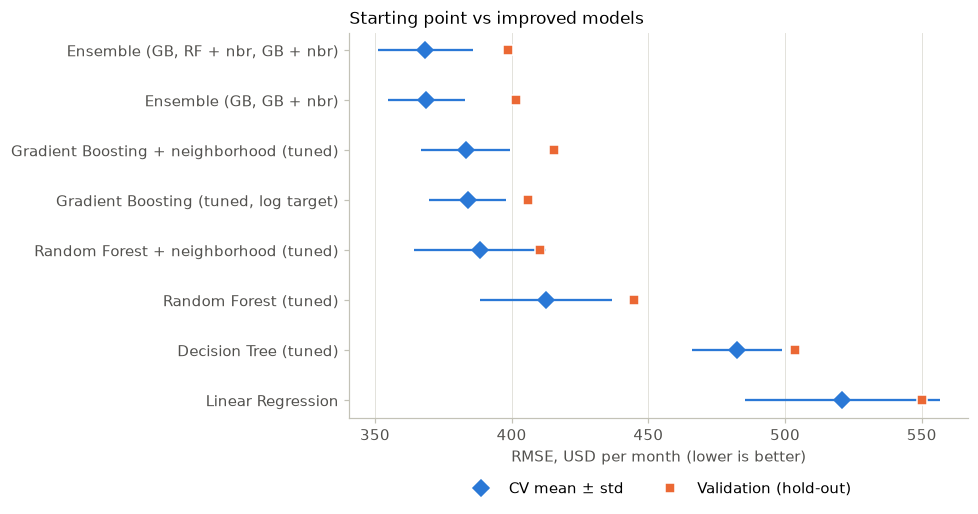

In [15]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK_2, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK_2, "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
})

r = final_table.iloc[::-1]
pos = np.arange(len(r))
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.grid(axis="y", visible=False)
ax.errorbar(r["CV RMSE"], pos, xerr=r["CV std"], fmt="D", markersize=7, color=BLUE, ecolor=BLUE,
            elinewidth=1.5, capsize=0, label="CV mean ± std", zorder=3)
ax.plot(r["Validation RMSE"], pos, "s", markersize=7, color=ORANGE, markeredgecolor="white",
        linestyle="none", label="Validation (hold-out)", zorder=4)
ax.set_yticks(pos, r.index)
ax.set_xlabel("RMSE, USD per month (lower is better)")
ax.set_title("Starting point vs improved models")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
plt.show()

In [16]:
# selection rule: walk up in complexity (best single model -> best pair -> three models) and move
# to the more complex model only if it is significantly better than the current choice
best_single = [n for n in final_table.index if not n.startswith("Ensemble")][0]
final_name = best_single
for challenger in [pair_name, triple_name]:
    t = paired_t(final_name, challenger)  # positive when the challenger has lower fold RMSE
    better = t > T_CRIT
    print(f"{challenger} vs {final_name}: CV RMSE {results[challenger].fold_rmse.mean():.2f} vs "
          f"{results[final_name].fold_rmse.mean():.2f}, t = {t:.2f} -> {'switch' if better else 'keep the simpler model'}")
    if better:
        final_name = challenger
print("\nSelected:", final_name)

Ensemble (GB, GB + nbr) vs Gradient Boosting + neighborhood (tuned): CV RMSE 368.77 vs 383.13, t = 4.93 -> switch
Ensemble (GB, RF + nbr, GB + nbr) vs Ensemble (GB, GB + nbr): CV RMSE 368.34 vs 368.77, t = 0.20 -> keep the simpler model

Selected: Ensemble (GB, GB + nbr)


**Final model: Ensemble (GB, GB + nbr)**, the equal-weight average of two Gradient Boosting models trained on `log(price)`:
1. Gradient Boosting from `04` on the original features (1000 trees, `learning_rate=0.1`, `max_depth=5`, `min_samples_leaf=5`, `subsample=0.8`, `max_features=0.5`);
2. the same model with the neighborhood features (`k=5`) and the re-tuned `max_depth=3`, `learning_rate=0.05`.

**Why this model:**
- **Validation performance:** CV RMSE 368.77 ± 14.03, which is 15.1 lower than the best required model (Gradient Boosting, 383.91). Validation RMSE 401.48 (MAE 233.1, R² 0.78), against 405.94. It is significantly better than the best single model (t = 4.93).
- **Simplicity over a tie:** the three-model average is only 0.42 lower on CV and better in just 2 of 5 folds (t = 0.20), so by the selection rule the simpler two-model ensemble is kept. It also needs no Random Forest.
- **Overfitting:** validation RMSE is 32.7 above CV RMSE, within the 14 to 38 shift that every model shows on this validation split in `05`. The neighborhood features are computed out-of-fold, so the CV estimate is not optimistic, and `04` showed that additional boosting stages do not increase the CV error.
- **Complexity and computational cost:** two models of 1000 trees each; training on all 7,398 rows takes a few seconds, which is not a constraint at this data size.
- **Interpretability:** low, as for any tree ensemble. Feature importances of the members give partial insight, and the neighborhood features themselves have a clear meaning (local price per square foot).
- **Validation alone is noisy:** the validation difference to Gradient Boosting alone (4.5) is within its uncertainty, which is why the selection relies on the 5-fold CV, as planned from the start.

## 8. Final training and predictions

The selected model is refit on **all 7,398 labeled rows** (training and validation parts together): the learning curves in `05` show that the error still decreases with more data, and the hyperparameters are fixed, so no further selection happens. The neighborhood features for the test rows are computed from all 7,398 labeled listings. The test set is used only here.

In [17]:
final_model = builders[final_name]()
print("Final model:", final_name)

t0 = time.perf_counter()
final_model.fit(X, y)
print(f"Final model fit on {len(X):,} rows in {time.perf_counter() - t0:.1f} s")

X_test = test_df.drop(columns=["ID"])
predictions = pd.DataFrame({"ID": test_df["ID"], "price": final_model.predict(X_test)})

Path("..").joinpath("predictions.csv").write_text(predictions.to_csv(index=False))
print("Saved ../predictions.csv")
predictions.head()

Final model: Ensemble (GB, GB + nbr)


Final model fit on 7,398 rows in 6.0 s
Saved ../predictions.csv


,ID,price
0,1,1698.135357
1,4,1700.087033
2,9,1094.286362
3,11,942.151828
4,13,774.023579


In [18]:
saved = pd.read_csv("../predictions.csv")
assert list(saved.columns) == ["ID", "price"]
assert len(saved) == len(test_df) and saved["ID"].is_unique
assert set(saved["ID"]) == set(test_df["ID"]) and (saved["ID"].to_numpy() == test_df["ID"].to_numpy()).all()
assert saved["price"].notna().all() and (saved["price"] > 0).all()
print(f"{len(saved):,} predictions, all test IDs present in the original order, no missing or non-positive values")

pd.DataFrame({
    "Training prices": y.describe(),
    "Predicted test prices": saved["price"].describe(),
}).round(0)

2,467 predictions, all test IDs present in the original order, no missing or non-positive values


,Training prices,Predicted test prices
count,7398.0,2467.0
mean,1463.0,1448.0
std,822.0,757.0
min,200.0,494.0
25%,949.0,988.0
50%,1274.0,1246.0
75%,1695.0,1646.0
max,8800.0,8053.0


**Summary**

- `predictions.csv` (repository root) contains 2,467 rows with `ID` and `price`: every test ID in the original order, no missing or non-positive values.
- The predicted prices have nearly the same median as the training prices (1,246 vs 1,274), a slightly lower mean (1,448 vs 1,463) and a smaller spread (std 757 vs 822): averaging models smooth predictions toward the middle of the price range, as the error analysis in `05` showed.
- The expected test RMSE lies between the CV estimate (369) and the validation result (401). The final model is trained on 7,398 rows, against 4,734 rows for each CV model and 5,918 for the validation check; according to the learning curves in `05`, more data should lower the error slightly.
- **Overall improvement:** from Linear Regression (CV RMSE 520.94) to the tuned single models (Gradient Boosting 383.91) through Grid Search and a log-transformed target, and to the final ensemble (368.77) through neighborhood features and averaging, all evaluated on the same folds and checked on the same validation set.